In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## t-sne

**Figure 3: t-SNE embedding of the penultimate-layer features of a ResNet-34 trained on CIFAR-10, for 100 CIFAR-10 test samples per class.** Colors mark the ten classes, numbered 1–10 in the legend. All ten classes are clearly separated: 94.2% of the points lie closer to their own class's centroid than to any other.

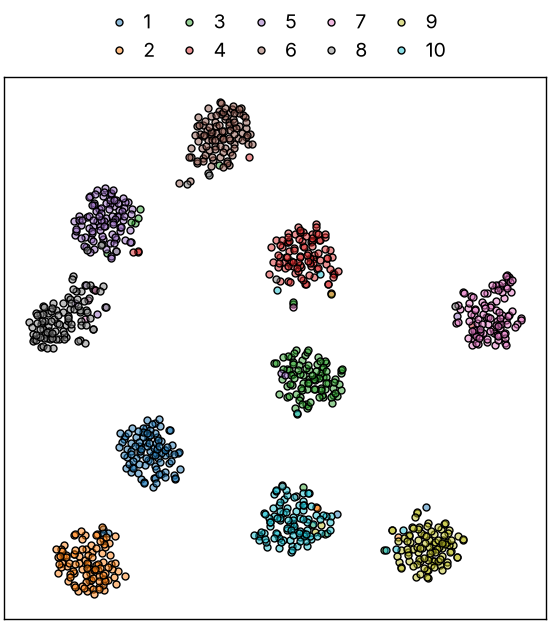

In [2]:
embedding = json.load(open("../data/t-sne.json"))
# ten classes need ten colors and the design has six series colors, so this figure uses matplotlib's tab10
PALETTE = plt.get_cmap("tab10").colors

fig, ax = plt.subplots(figsize=(2.75, 2.75))
for i in range(10):
    points = embedding[f"class_{i + 1}"]
    ax.plot(points["x"], points["y"], "o", markeredgecolor=colors["ink"], markerfacecolor=(*PALETTE[i], 0.5), linestyle="none",
            label=f"{i + 1}")

ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, ncol=5, frameon=False)
fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/t-sne.pdf")
fig.savefig("../outputs/t-sne.png")
plt.show()